#### LinearRegression().fit()
- Minimizes the residual sum of squares between the observed targets in dataset and the targets predicted by the linear approximation. 
- 
- This method in python scikit-learn library is used to train a linear regression model.It takes the input data and corresponding target values and calculate the optimal coefficients for linear equations that best fits the data.

- 18th June,2025.

In [2]:
'''18th June,2025.'''
import pickle as pkl
import numpy as np
with open("data/train.pkl","rb") as f:
    train_data=pkl.load(f)

with open("data/test.pkl","rb") as f:
    test_data=pkl.load(f)

#print("train_data=",train_data)
#print("test_data=",test_data)
#print(len(train_data))
#print(len(test_data))

train_data=np.array(train_data)
test_data=np.array(test_data)

x_train=train_data[:,0].reshape(-1,1)# reshape() is used to convert the array into 2D array of same number of rows and 1 column as train_data
y_train=train_data[:,1] 
print("x_train=",x_train)
print("y_train=",y_train)
x_test=test_data[:,0].reshape(80,1)
#x_test=test_data[:,0].reshape(-1,1)
y_test= test_data[:,1]

print("x_test=",x_test)
print("y_test=",y_test)


x_train= [[ 27.42765666]
 [ -4.96183456]
 [-27.86119551]
 ...
 [ 27.54602153]
 [  8.97475985]
 [-19.66451461]]
y_train= [3335.78295109 2647.40265244  520.73369536 ... 1729.42858449 1264.43870071
  -54.2662792 ]
x_test= [[-15.029]
 [-25.977]
 [ -4.48 ]
 [  2.527]
 [ 18.039]
 [-25.795]
 [ 31.794]
 [  6.804]
 [  8.512]
 [ 22.505]
 [ 26.159]
 [ 23.114]
 [  4.291]
 [ -5.684]
 [-32.41 ]
 [  2.667]
 [ -1.673]
 [ -3.507]
 [-34.867]
 [ -1.008]
 [  1.197]
 [-22.883]
 [ 27.132]
 [ -4.557]
 [  2.968]
 [-26.747]
 [  7.406]
 [-20.874]
 [-34.174]
 [-22.988]
 [ 34.37 ]
 [-16.604]
 [ 27.517]
 [-11.319]
 [ 10.003]
 [-32.333]
 [ 29.414]
 [ 30.961]
 [-28.875]
 [-22.89 ]
 [ 25.921]
 [ -5.691]
 [-34.097]
 [-21.021]
 [ 32.011]
 [ 16.807]
 [ 21.049]
 [-29.848]
 [ 18.417]
 [-32.466]
 [-32.837]
 [ 11.921]
 [ 22.428]
 [-13.79 ]
 [  8.554]
 [ 22.393]
 [ 14.896]
 [ 15.155]
 [ -7.952]
 [-28.154]
 [ -7.434]
 [  0.693]
 [-15.841]
 [  9.45 ]
 [ -4.655]
 [-34.482]
 [ -5.866]
 [  1.617]
 [ 25.48 ]
 [-19.075]
 [ 13.237]


- 19th June,2025.

In [3]:
combine = list(zip(x_train,y_train))
# zip() is used to combine x_train and y_train
np.random.shuffle(combine)
print(len(combine))

split_data=[combine[i::16]for i in range(16)]
print(len(split_data[0]))
#print(split_data.shape)-> Won't work for lists;works only for numpy arrays

train_sets=[]
for subset in split_data:
    #To maintain order while splitting data
    #Unzip data in combine and store in train_sets
    x_sub=np.array([row[0] for row in subset]).reshape(-1,1)
    y_sub=np.array([row[1] for row in subset])
    train_sets.append((x_sub,y_sub))
print(x_sub)


8000
500
[[ 30.18776822]
 [ 27.01381932]
 [-15.628456  ]
 [ 18.79675263]
 [ 10.03651187]
 [ 26.85305517]
 [-12.69361555]
 [ 22.2062751 ]
 [ 17.48903104]
 [ 25.43442916]
 [  9.2844872 ]
 [  5.58883257]
 [ -8.46660684]
 [ 34.25481471]
 [  5.90826854]
 [-26.38290293]
 [-14.95779467]
 [ 12.9973468 ]
 [-17.10026541]
 [-18.96275761]
 [ 14.19723945]
 [ 10.66904489]
 [  0.94984566]
 [-18.19382597]
 [  7.31050318]
 [ 18.76807086]
 [ -2.83237116]
 [  8.88806628]
 [ 21.1234796 ]
 [  7.96862521]
 [ -4.70758448]
 [  8.70279142]
 [-21.56047163]
 [ 29.07984869]
 [-30.3761691 ]
 [  6.12535376]
 [-17.79648185]
 [ 22.31897653]
 [-33.94685668]
 [ 21.8621419 ]
 [ -0.96272575]
 [  5.31437488]
 [-26.50455346]
 [  9.83428229]
 [ 29.53586616]
 [-25.83364866]
 [-23.73547849]
 [ 24.00410662]
 [ -0.48582447]
 [ -2.61851955]
 [-34.40131528]
 [ 31.88633987]
 [ 20.20088185]
 [ 18.44799474]
 [  5.71389224]
 [ -4.27970465]
 [-33.74992025]
 [-32.58227789]
 [  5.42070412]
 [ 12.59490893]
 [ 33.51898049]
 [ 24.77082946]

- Creation of Model
- 20th June,2025.

In [4]:
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.linear_model import LinearRegression 

degrees = range(1,16)

bias_list=[]
'''Training Error is low, Testing Error is high -due to variance
    When both errors are high then it is due to bias '''
variance_list = []

for degree in degrees:
    predictions = []
    for x_sub,y_sub in train_sets:
        poly = PolynomialFeatures(degree)
        print(poly)
        #this adds the polynomial features to the training data
        x_poly=poly.fit_transform(x_sub)
        #print(x_poly)
        #Initializes and fits the Linear Regression models using the polynomial features as input
        #  and the labels y_sub-> Doubt- what is this labels y_sub ? y_sub is output
        model=LinearRegression().fit(x_poly,y_sub)
        print(model)
        #transforms the same test data x_test using the same polynomial transformer so that it matches the input shape used to train the model
        x_test_poly = poly.transform(x_test)
        #Uses the trained model to predict outputs for the polynomial-transformed test data
        y_predict= model.predict(x_test_poly)
        #Stores the model's predictions for later use in bias-variance calculation
        predictions.append(y_predict)
    
    predictions=np.array(predictions)
    average_predictions=np.mean(predictions,axis=0)
    bias=np.mean((average_predictions - y_test)**2)
    variance = np.mean(np.var(predictions, axis=0))
    bias_list.append(bias)
    variance_list.append(variance)
        


PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures(degree=1)
LinearRegression()
PolynomialFeatures()
LinearRegression()
PolynomialFeatures()
LinearRegression()
PolynomialFeatures()
LinearRegression()
PolynomialFeatures()
LinearRegression()
PolynomialFeatures()
LinearRegression()
PolynomialFeatures()
LinearRegre

- 24th June,2025.


In [5]:
import pandas as pd
df = pd.DataFrame({"degree":degrees,"bias":bias_list,"variance":variance_list})
print(df)


    degree           bias       variance
0        1  492143.079250   35668.019640
1        2  467834.046962   37995.324682
2        3    4141.445409   55057.856844
3        4    3836.388214   70554.208199
4        5    3139.852212   92064.002461
5        6    2774.924579  116352.623467
6        7    3980.727227  140856.121014
7        8    4247.060951  151794.415546
8        9    4604.424638  176565.749269
9       10    5323.062675  164835.594938
10      11    6675.876263  173672.602591
11      12    9537.764524  176812.705658
12      13   16150.887908  182427.638413
13      14   21187.251857  178966.465776
14      15   29942.394448  173260.136850


#### Task 3:Calculating Irreducible Error
- 24th June,2025.

- Irreducible error is a part of total error that can not be reduced by any model no matter how complex it is. 
- It comes from noise of the data and natural randomness in target variable.
- How to estimate irreducible error in this task ? That is,
expected test error = bias^2 + variance+irreducible error 
- So, we can calculate irreducible error by formula MSE - (bias^2+variance)

In [6]:
irreducible_error = []
mean_square_error = []
# To get an indexed list we use enumerate
for i,degree in enumerate(degrees):
    predictions = []
    for x_sub,y_sub in train_sets:
        #Creates number of parameters according to number of features
        poly=PolynomialFeatures(degree)
        #this adds the polynomial features to the training data
        x_poly=poly.fit_transform(x_sub)
        model=LinearRegression().fit(x_poly,y_sub)
        #transforms the same test data x_test using the same polynomial transformer so that it matches the input shape used to train the model
        x_test_poly=poly.transform(x_test)
        #Uses the trained model to predict outputs for the polynomial-transformed test data
        y_predict=model.predict(x_test_poly)
        #Stores the model's predictions for later use in bias-variance calculation
        predictions.append(y_predict)
    predictions=np.array(predictions)
    MSE = np.mean((predictions-y_test)**2)
    mean_square_error.append(MSE)
    irreducible = MSE - (bias_list[i]+variance_list[i])
    irreducible_error.append(irreducible)

print(irreducible_error)
        

[1.1641532182693481e-10, -5.820766091346741e-11, -7.275957614183426e-12, 0.0, 0.0, 2.9103830456733704e-11, 2.9103830456733704e-11, 0.0, 0.0, -2.9103830456733704e-11, 0.0, 2.9103830456733704e-11, 0.0, 2.9103830456733704e-11, 0.0]


- 25th June,2025.

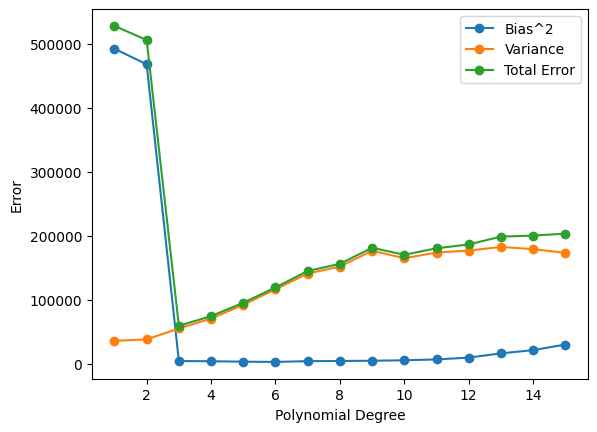

In [8]:
import matplotlib.pyplot as plt 

plt.plot(degrees,bias_list,label="Bias^2",marker='o')
plt.plot(degrees,variance_list,label="Variance",marker='o')
plt.plot(degrees,mean_square_error,label="Total Error",marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("Error")

plt.legend()


#### Report 
- Underfit for polynomials of degrees 1 to 2 
- - Bias is high due to model being too simple to capture the relationship and variance is low since all models are similarly poor and total error is high.

- Optimalfit for polynomials of degrees 3 and 4
- - Bias decreases and variance slightly increases . Total error reaches a minimum value meaning best generalization.
This is ideal balance point.

- Overfit for polynomials of degree 5 and higher uptill 15 
- - Bias is very low but variance is very high as the model fluctuates a lot with different training subsets and total error rises again due to overfitting.
